## Laura Ralston Professor Eample

In [18]:
import numpy as np 
import pandas as pd
import sympy 
import scipy
import seaborn as sns
import matplotlib.pyplot as plt

### Sataement and Data Setup

What's the average age of a GHC student in spring 2021?
variable   : Age in years  &rarr; quantitative <span style="color:yellow">discrete number? (dtype : int)  </span> 
<hr>
population : all 5593 GHC students enrolled in spring 2021. <br>
parameter  : average age in years of 5593 students enrolled in spring 2021.
<hr>
sample     : 12 students in Math <br>
statistic  : varaible 

### Data Collection

In [5]:
raw_data_std_age_l_r=np.array([ [19,19,19],
                                [18,18,18],
                                [19,19,26],
                                [20,20,19] ],dtype="int")
sympy.sympify(raw_data_std_age_l_r)

[[19, 19, 19], [18, 18, 18], [19, 19, 26], [20, 20, 19]]

In [6]:
len(raw_data_std_age_l_r.flatten()) # samplesize  n =12

12

### Processing

#### Bins-cut

In [7]:
df_st_age = pd.DataFrame(raw_data_std_age_l_r.flatten())
df_st_age
df_st_age['pd_interva'] =pd.cut(df_st_age[0],bins=3)
df_st_age['pd_mannual'] =pd.cut(df_st_age[0],bins=[15,19,20,24,25,29])
mapper = df_st_age['pd_mannual'].value_counts().to_dict()
df_st_age["count"]=df_st_age['pd_mannual'].map(mapper)
df_st_age

,0,pd_interva,pd_mannual,count
0,19,"(17.992, 20.667]","(15, 19]",9
1,19,"(17.992, 20.667]","(15, 19]",9
2,19,"(17.992, 20.667]","(15, 19]",9
3,18,"(17.992, 20.667]","(15, 19]",9
4,18,"(17.992, 20.667]","(15, 19]",9
5,18,"(17.992, 20.667]","(15, 19]",9
6,19,"(17.992, 20.667]","(15, 19]",9
7,19,"(17.992, 20.667]","(15, 19]",9
8,26,"(23.333, 26.0]","(25, 29]",1
9,20,"(17.992, 20.667]","(19, 20]",2


#### summing up

In [9]:
df =pd.DataFrame(data= [["15-19","|||||||||",9,"$\\frac{9}{12} \\quad  0.750 \\quad   75\\%$" ,9/12],
                        ["20-24","||"       ,2,"$\\frac{2}{12} \\quad  0.170 \\quad   17\\%$" ,2/12],
                        ["25-29","|"        ,1,"$\\frac{1}{12} \\quad  0.083 \\quad   8.3\\%$",1/12]],
                 index   =["Age_group1","Age_group2","Age_group3"],
                 columns =[["Grouped Frequency Distribution","Grouped Frequency Distribution","Grouped Frequency Distribution","Grouped Frequency Distribution","Grouped Frequency Distribution"],
                           ["Count by '5'(class|bin width)","Count by '5'(class|bin width)","Count by '5'(class|bin width)","Count by '5'(class|bin width)","Count by '5'(class|bin width)"],
                           ["Ages","Tally_Symbol","Frequency|Count","Expression","Decimal_Cal"]])
df.loc["Total | Comments",( "Grouped Frequency Distribution","Count by '5'(class|bin width)",
                 "Frequency|Count" ) ] =df[( "Grouped Frequency Distribution","Count by '5'(class|bin width)",
                 "Frequency|Count" ) ].sum()
df.loc["Total | Comments",( "Grouped Frequency Distribution","Count by '5'(class|bin width)",
                 "Decimal_Cal" ) ] =df[( "Grouped Frequency Distribution","Count by '5'(class|bin width)",
                 "Decimal_Cal" ) ].sum()
df[("Grouped Frequency Distribution","Count by '5'(class|bin width)",'Decimal_Cal')]=df[("Grouped Frequency Distribution","Count by '5'(class|bin width)",'Decimal_Cal')].apply(lambda x : "{:.2f}".format(x))
df.loc["Total | Comments",("Grouped Frequency Distribution","Count by '5'(class|bin width)",
                ['Ages',"Tally_Symbol","Expression"])]= ["75% of students are","between 15 and 19 years old","Outerliers : 18, 26 "]
df_Laura_Ralston=df.copy()
df.index.name="Groups"
df

Grouped Frequency Distribution                               \
                  Count by '5'(class|bin width)                                
                                           Ages                 Tally_Symbol   
Groups                                                                         
Age_group1                                15-19                    |||||||||   
Age_group2                                20-24                           ||   
Age_group3                                25-29                            |   
Total | Comments            75% of students are  between 15 and 19 years old   

                                                                             \
                                                                              
                 Frequency|Count                                 Expression   
Groups                                                                        
Age_group1                     9   $\frac{9}{12} \quad  0.750 \quad   75\%$   
Age_group2                     2   $\frac{2}{12} \quad  0.170 \quad   17\%$   
Age_group3                     1  $\frac{1}{12} \quad  0.083 \quad   8.3\%$   
Total | Comments              12                       Outerliers : 18, 26    

                              
                              
                 Decimal_Cal  
Groups                        
Age_group1              0.75  
Age_group2              0.17  
Age_group3              0.08  
Total | Comments        1.00

#### styling table

In [10]:
df_Laura_Ralston.style.set_table_styles([
    {"selector":"td.row3.col0,td.row3.col1,td.row3.col3","props":"background-color:cyan;color:indigo;border:double white 2px"},
    {"selector":"td","props":"border:solid cyan 2px;text-align:center"},
    {"selector":" ","props":"border:solid yellow 5px"},
    {"selector":"th","props":"border:double lightblue 3px;font-size:16px;font-weight:bold"},
]).background_gradient(cmap="rainbow")

### Visualize Data

#### 1 bar or histogram

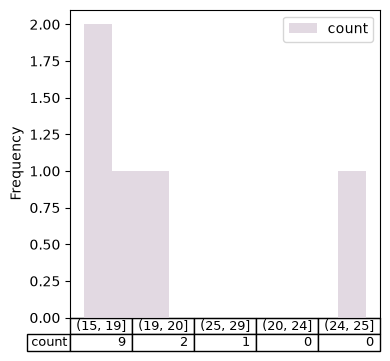

In [13]:
plt.figure(figsize=(4,4))
df_st_age['pd_mannual'].value_counts().sort_values(ascending=False).\
    plot(kind="hist",legend=True,colormap="twilight",
         table=True,stacked=False,xticks=[],xlabel="")
plt.show()

#### 2 Stem and Leaf plot 

<Figure size 400x400 with 0 Axes>

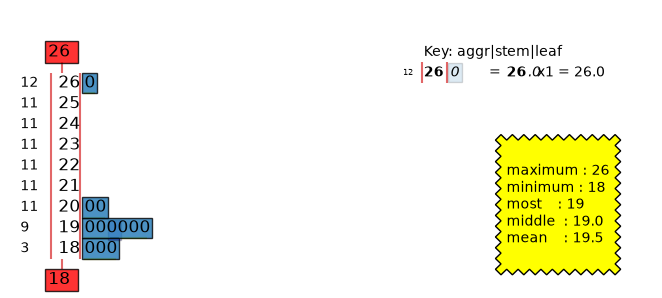

In [16]:
import stemgraphic
data =raw_data_std_age_l_r.flatten()
# Create a stem-and-leaf plot
plt.figure(figsize=(4,4))
fig, ax = stemgraphic.stem_graphic( data,
                                    outliers=True,outliers_color="red",alpha=0.8,
                                    median_alpha=0.25,
                                    median_color='blue',
                                    underline_color="yellow",
                                    bar_color='C0',
                                    bar_outline="black",)
ax.annotate("""
maximum : {}
minimum : {}
most    : {}
middle  : {}
mean    : {}
""".format(data.max(),data.min(),scipy.stats.mode(data)[0],np.median(data),data.mean())
            ,xy=(23,0),
            bbox=dict(boxstyle="sawtooth,pad=0.8",facecolor="yellow"))
plt.show()

#### 3 kde plot

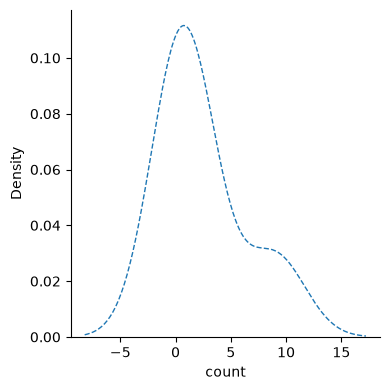

In [19]:
sns.displot(df_st_age['pd_mannual'].value_counts(),kind="kde",height=4,aspect=1,lw=1,ls="--")
plt.show()